# Binary recovery with grid search and HMC

> **Install:** this tutorial needs the `plots` extra (ChainConsumer) and, for its "As a pipeline" section, the `pipeline` extra: `pip install "virgil-astro[plots,pipeline]"`.

Looking for faint companions at high resolution is often the first thing you do with an interferometric dataset, and often why you took it.

This tutorial recovers a binary from synthetic observables: a coarse likelihood grid first, then Hamiltonian Monte Carlo (HMC), plain and Fisher-reparametrized.

First, the imports.

In [1]:
import warnings
import jax
import jax.numpy as jnp
import numpy as onp
import matplotlib.pyplot as plt
from jax.flatten_util import ravel_pytree

warnings.filterwarnings("ignore", message="IProgress not found.*")

import numpyro
import numpyro.distributions as dist
from numpyro.infer import MCMC, NUTS
from numpyro.infer.initialization import init_to_value

from virgil.grid_fit import likelihood_grid
from virgil.inference import fisher_projection, hessian_matrix
from virgil.likelihood import loglike, posterior_predictive_summary
from virgil.models import BinaryModelCartesian
from virgil.oidata import OIData
from virgil.plotting import (
    set_style,
    plot_data_model_correlation,
    plot_grid_map,
    plot_chainconsumer_diagnostics,
    diagnostics_table_from_samples,
    truth_cartesian_and_polar,
)

set_style()  # the figure style used throughout the docs

## Simulate Data

We simulate $V^2$ and phases from a known binary, add realistic noise, and wrap the result in the `OIData` object that `virgil` uses for data.

In [2]:
rng = onp.random.default_rng(42)
n_bl = 24
u = jnp.array(rng.uniform(-28.0, 28.0, size=n_bl))
v = jnp.array(rng.uniform(-28.0, 28.0, size=n_bl))
wavel = jnp.array([4.8e-6])

truth = {"dra": 120.0, "ddec": -80.0, "flux": 4e-3}
model_true = BinaryModelCartesian(**truth)
cvis_true = model_true.model(u, v, wavel)

vis_true = jnp.abs(cvis_true) ** 2
phi_true = jnp.rad2deg(jnp.angle(cvis_true))

# Synthetic noise as percentage of data scale (phase in degrees), boosted SNR by 5x.
vis_scale = jnp.maximum(jnp.median(vis_true), 1e-6)
phi_scale = jnp.maximum(jnp.median(jnp.abs(phi_true)), 5.0)
d_vis = 0.001 * vis_scale * jnp.ones_like(vis_true)
d_phi = 0.004 * phi_scale * jnp.ones_like(phi_true)

vis_obs = vis_true + d_vis * jnp.array(rng.normal(size=vis_true.shape))
phi_obs = phi_true + d_phi * jnp.array(rng.normal(size=phi_true.shape))

data = OIData(
    {
        "u": u,
        "v": v,
        "wavel": wavel,
        "vis": vis_obs,
        "d_vis": d_vis,
        "phi": phi_obs,
        "d_phi": d_phi,
        "phi_unit": "deg",
        "i_cps1": None,
        "i_cps2": None,
        "i_cps3": None,
        "v2_flag": True,
        "cp_flag": False,
    }
)

## Grid Search for Companions

JAX makes grid searches fast and easy to parallelize, so start any companion search here.

Define the grid dictionary `samples` in your chosen coordinates. We use Cartesian $(\Delta\mathrm{RA}, \Delta\mathrm{Dec}, \mathrm{flux})$; for separation, position angle and flux, use `BinaryModelAngular` instead.

In [3]:
samples = {
    "dra": jnp.linspace(-250.0, 250.0, 81),
    "ddec": jnp.linspace(-250.0, 250.0, 81),
    "flux": 10 ** jnp.linspace(-4.5, -1.5, 60),
}

ll_cube = likelihood_grid(BinaryModelCartesian, data=data, grid=samples)
max_idx = jnp.unravel_index(jnp.argmax(ll_cube), ll_cube.shape)
grid_est = {
    "dra": float(samples["dra"][max_idx[0]]),
    "ddec": float(samples["ddec"][max_idx[1]]),
    "flux": float(samples["flux"][max_idx[2]]),
}

print(
    "Grid estimate: dra={:.3g} mas, ddec={:.3g} mas, flux={:.2g}".format(
        grid_est["dra"], grid_est["ddec"], grid_est["flux"]
    )
)

Grid estimate: dra=119 mas, ddec=-81.2 mas, flux=0.0038


## Visualize the Grid
The plotting helpers give a consistent style and handle the metadata. The grid search alone recovers the binary accurately.

How significant is the best grid point? That needs the distribution of the search's best statistic under noise alone, which [Detection ROC curves](detection_roc.md) simulates.

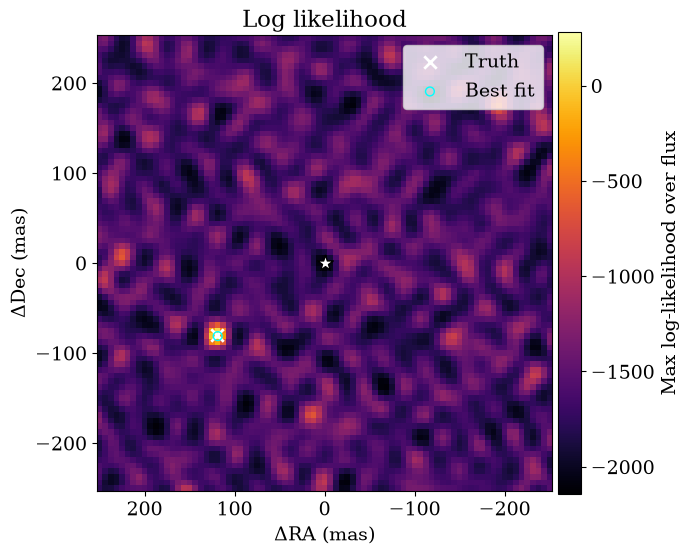

In [4]:
# The full grid is reduced to the maximum log likelihood over flux at each
# (dra, ddec).
plot_grid_map(
    ll_cube,
    samples,
    truth=truth,
    best=grid_est,
    label="Max log-likelihood over flux",
);

## Uncertainty quantification with Hamiltonian Monte Carlo

Samplers such as [Metropolis-Hastings](https://en.wikipedia.org/wiki/Metropolis%E2%80%93Hastings_algorithm) or [`emcee`](http://emcee.readthedocs.io/) often struggle in high dimensions. With JAX gradients we can use [Hamiltonian Monte Carlo](https://arxiv.org/abs/1701.02434), which scales to many parameters, through [`numpyro`](https://num.pyro.ai/en/stable/):

In [5]:
params = ["dra", "ddec", "flux"]


# Define a simple physical-parameter HMC model with bounded priors.
def model_hmc(oidata):
    dra = numpyro.sample("dra", dist.Uniform(-300.0, 300.0))
    ddec = numpyro.sample("ddec", dist.Uniform(-300.0, 300.0))
    log10_flux = numpyro.sample("log10_flux", dist.Uniform(-6.0, -1.0))
    flux = 10.0**log10_flux
    ll = loglike([dra, ddec, flux], params, BinaryModelCartesian, oidata)
    numpyro.factor("loglike", ll)


# Initialize near the grid maximum for robust convergence in this toy setup.
init_values = {
    "dra": float(grid_est["dra"]),
    "ddec": float(grid_est["ddec"]),
    "log10_flux": float(jnp.log10(max(grid_est["flux"], 1e-12))),
}
kernel = NUTS(model_hmc, init_strategy=init_to_value(values=init_values))
mcmc = MCMC(
    kernel, num_warmup=800, num_samples=2000, num_chains=1, progress_bar=False
)
mcmc.run(jax.random.PRNGKey(2026), oidata=data)
posterior = mcmc.get_samples()

summary = {
    "dra_median": float(jnp.median(posterior["dra"])),
    "ddec_median": float(jnp.median(posterior["ddec"])),
    "flux_median": float(jnp.median(10.0 ** posterior["log10_flux"])),
}
print(
    "HMC estimate: dra={:.3g} mas, ddec={:.3g} mas, flux={:.2g}".format(
        summary["dra_median"], summary["ddec_median"], summary["flux_median"]
    )
)

HMC estimate: dra=120 mas, ddec=-80.1 mas, flux=0.0039


## Diagnostic Tables
Helper functions turn the posterior draws into a dataframe.

In [6]:
# Convert vanilla posterior samples into diagnostics table for later comparison plots.
hmc_results = diagnostics_table_from_samples(
    posterior,
    flux_key="log10_flux",
    log10_flux=True,
)

print(
    "HMC estimate from diagnostics table: dra={:.3g} mas, ddec={:.3g} mas, flux={:.2g}".format(
        float(hmc_results["dra"].median()),
        float(hmc_results["ddec"].median()),
        float(hmc_results["flux"].median()),
    )
)

HMC estimate from diagnostics table: dra=120 mas, ddec=-80.1 mas, flux=0.0039


## Fisher Reparametrization
If HMC converges slowly on high-SNR data, the cause is often strong correlations between parameters. [`zodiax`](https://github.com/LouisDesdoigts/zodiax), the backend of `virgil`, can reparametrize a problem into its natural scales, from fiducial values `x0` and the [Fisher Information Matrix](https://en.wikipedia.org/wiki/Fisher_information).

See [this `zodiax` tutorial](https://github.com/LouisDesdoigts/zodiax_tutorials/blob/main/tutorials/optimisation_tools.ipynb) for more.

In [7]:
x0_dict = {
    "dra": grid_est["dra"],
    "ddec": grid_est["ddec"],
    "log10_flux": float(jnp.log10(max(grid_est["flux"], 1e-12))),
}
x0, unravel = ravel_pytree(x0_dict)


# Build local Fisher geometry around x0 for whitening transform.
def objective(x):
    xdict = unravel(x)
    flux = 10.0 ** xdict["log10_flux"]
    values = jnp.array([xdict["dra"], xdict["ddec"], flux])
    return -loglike(values, params, BinaryModelCartesian, data)


F = hessian_matrix(objective, x0)
P = fisher_projection(F)


# Sample in latent coordinates and apply explicit prior correction back to physical priors.
def model_hmc_fisher(oidata):
    u_latent = numpyro.sample(
        "u", dist.Normal(0.0, 1.0).expand([x0.shape[0]]).to_event(1)
    )
    log_q_u = dist.Normal(0.0, 1.0).log_prob(u_latent).sum()
    x = x0 + jnp.dot(
        P, u_latent
    )  # this maps it to the original physical space
    xdict = unravel(x)
    dra = xdict["dra"]
    ddec = xdict["ddec"]
    log10_flux = xdict["log10_flux"]
    flux = 10.0**log10_flux
    numpyro.deterministic("dra", dra)
    numpyro.deterministic("ddec", ddec)
    numpyro.deterministic("flux", flux)
    log_prior_x = (
        dist.Uniform(-300.0, 300.0).log_prob(dra)
        + dist.Uniform(-300.0, 300.0).log_prob(ddec)
        + dist.Uniform(-6.0, -1.0).log_prob(log10_flux)
    )
    numpyro.factor("prior_correction", log_prior_x - log_q_u)
    numpyro.factor(
        "loglike",
        loglike([dra, ddec, flux], params, BinaryModelCartesian, oidata),
    )


kernel_f = NUTS(model_hmc_fisher)
mcmc_f = MCMC(
    kernel_f,
    num_warmup=800,
    num_samples=2000,
    num_chains=1,
    progress_bar=False,
)
mcmc_f.run(jax.random.PRNGKey(2027), oidata=data)
post_f = mcmc_f.get_samples()


print(
    "Fisher HMC estimate: dra={:.3g} mas, ddec={:.3g} mas, flux={:.2g}".format(
        float(jnp.median(post_f["dra"])),
        float(jnp.median(post_f["ddec"])),
        float(jnp.median(post_f["flux"])),
    )
)

Fisher HMC estimate: dra=120 mas, ddec=-80.1 mas, flux=0.0039


## Converting coordinate systems

The sample reformatter also converts coordinates:

In [8]:
# Convert Fisher-HMC posterior samples and prepare shared diagnostic tables.
fisher_results = diagnostics_table_from_samples(post_f)
truth_cart, truth_polar = truth_cartesian_and_polar(truth)

print(
    "Fisher HMC estimate: sep={:.3g} mas, pa={:.3g} deg".format(
        float(fisher_results["sep"].median()),
        float(fisher_results["pa"].median()),
    )
)

Fisher HMC estimate: sep=144 mas, pa=124 deg


Corner plots can come from anything you like, e.g. [corner.py](https://corner.readthedocs.io/en/latest/) or [pairplots](https://sefffal.github.io/PairPlots.jl/dev/); virgil has default helpers for chainconsumer.

The Fisher and default parametrizations work equally well, recovering the true values to about 1σ. The first plot is a corner plot. The second is a trace: check that the chains look stationary. `chainconsumer` and similar packages also give convergence diagnostics.

findfont: Failed to find font weight medium for DejaVu Sans, now using 400.


findfont: Failed to find font weight medium for DejaVu Sans, now using 400.


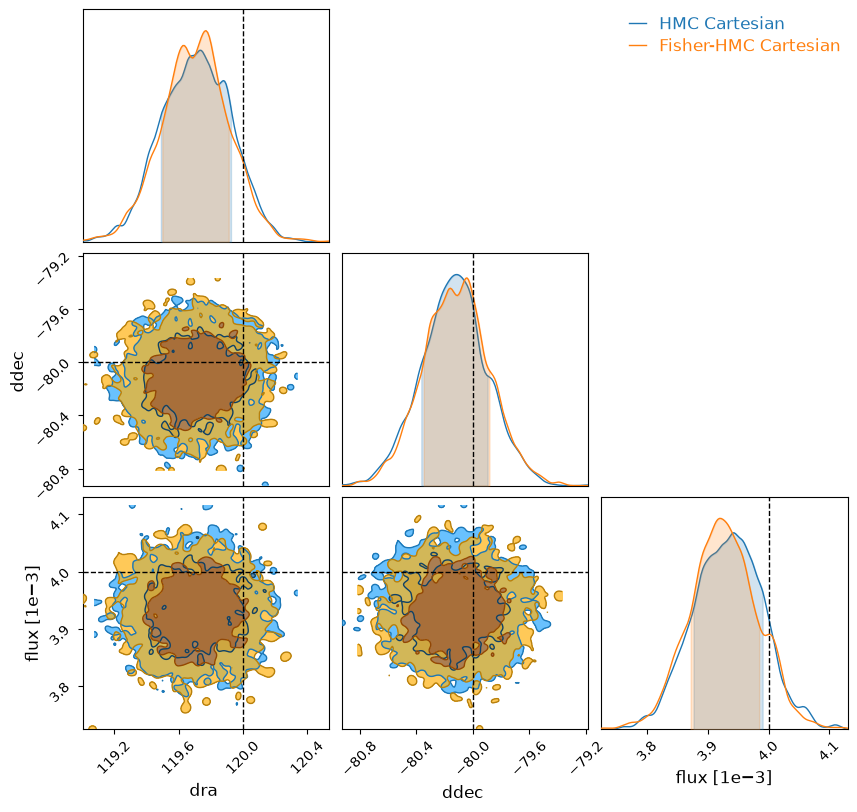

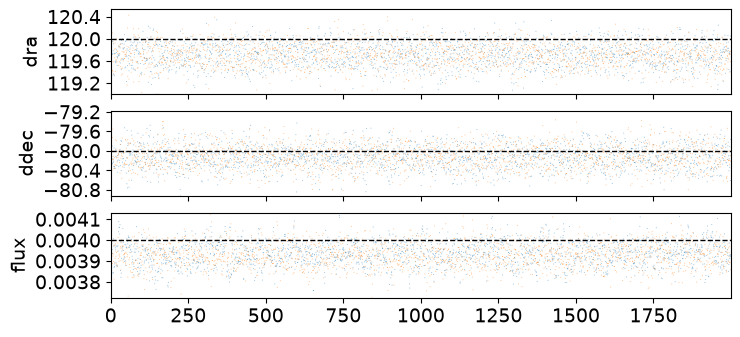

In [9]:
# Cartesian comparison plot
plot_chainconsumer_diagnostics(
    {
        "HMC Cartesian": hmc_results,
        "Fisher-HMC Cartesian": fisher_results,
    },
    columns=["dra", "ddec", "flux"],
    truth=truth_cart,
    colors=["#1f77b4", "#ff7f0e"],
);

And in polar coordinates:

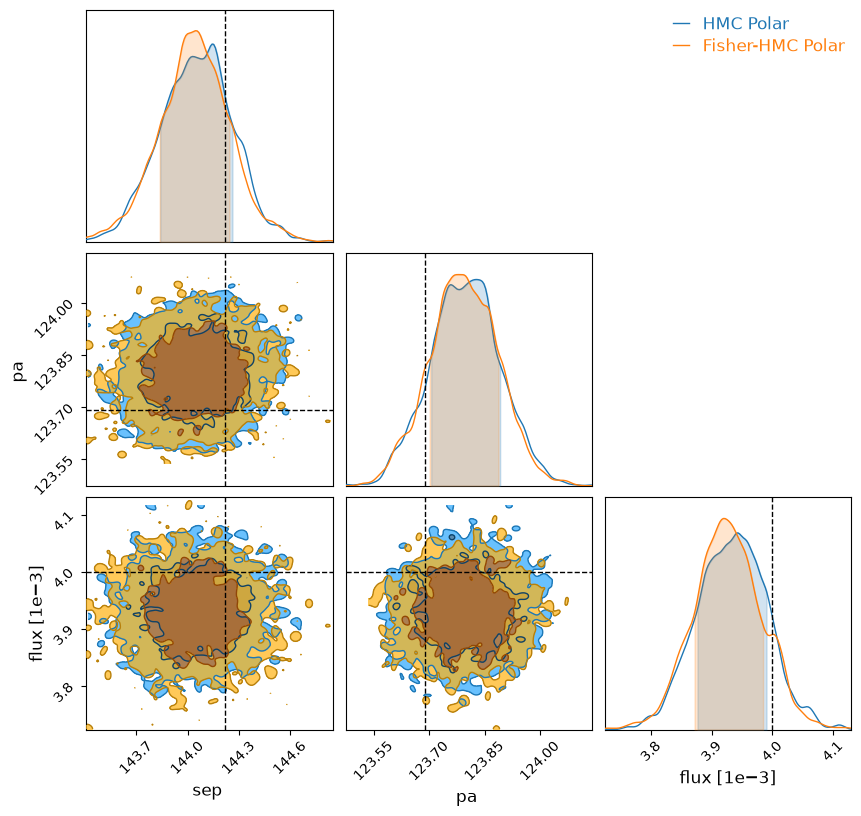

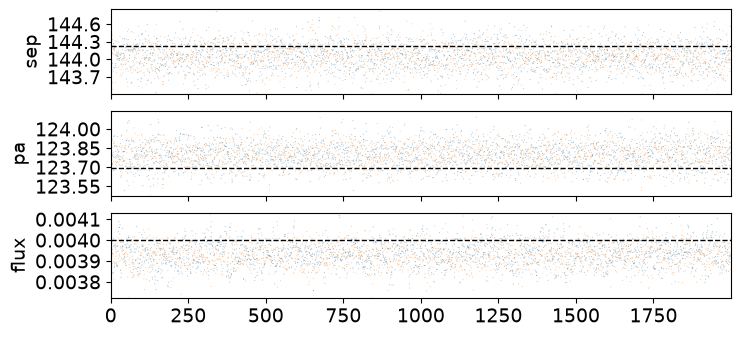

In [10]:
# Polar comparison plot
plot_chainconsumer_diagnostics(
    {
        "HMC Polar": hmc_results,
        "Fisher-HMC Polar": fisher_results,
    },
    columns=["sep", "pa", "flux"],
    truth=truth_polar,
    colors=["#1f77b4", "#ff7f0e"],
);

## Posterior Predictive Checks with Correlation Plots

*Always* compare the posterior predictions with the data. Interferometric data are hard to visualize, so the usual check is a 1:1 correlation plot of data against model.

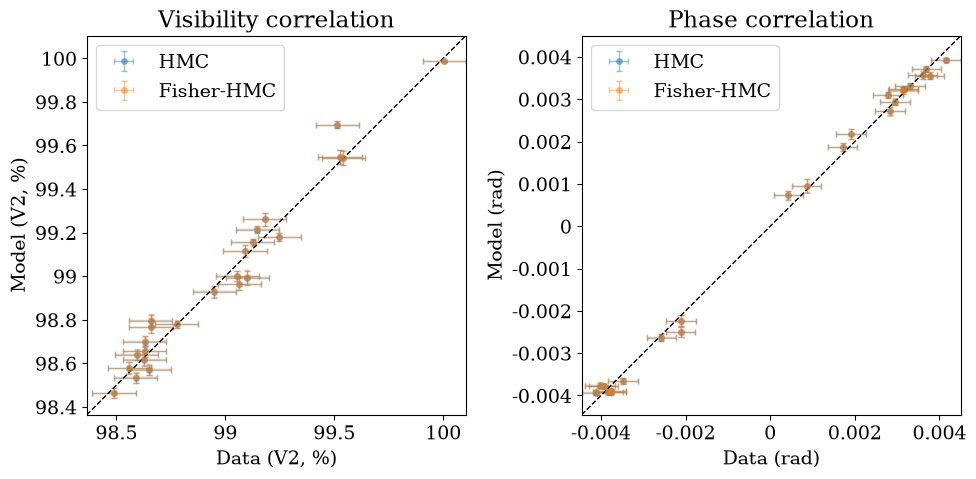

In [11]:
# Posterior predictive correlation: data vs model (HMC and Fisher-HMC)
hmc_samples = {
    "dra": posterior["dra"],
    "ddec": posterior["ddec"],
    "flux": 10.0 ** posterior["log10_flux"],
}
hmc_pred = posterior_predictive_summary(hmc_samples, BinaryModelCartesian, data)

fisher_samples = {key: post_f[key] for key in ("dra", "ddec", "flux")}
fisher_pred = posterior_predictive_summary(
    fisher_samples, BinaryModelCartesian, data
)

plot_data_model_correlation(
    data,
    {"HMC": hmc_pred, "Fisher-HMC": fisher_pred},
    colors=["C0", "C1"],
)
plt.show()

## As a pipeline

[`BinaryPipeline`](pipeline.md) runs everything above in one call, fixes the order of the steps and writes a run folder that reloads without recomputing. The grid search and maps are its `search` stage, the maximum-likelihood point starts its `fit` stage, and the HMC chains are its `posterior` stage. The cell below sets only this notebook's choices: the same $\pm 250$ mas grid of 81 points per axis, the same flux range over 60 points and the same sampler length. Its priors are the pipeline's group-invariant defaults (uniform in position, log-uniform in flux), so the posterior matches the hand-written one to within sampling noise, not exactly.

In [12]:
from tempfile import mkdtemp

from virgil.pipeline import BinaryPipeline

res = BinaryPipeline(
    data,
    BinaryModelCartesian(dra=100.0, ddec=-100.0, flux=1e-3),
    output=f"{mkdtemp()}/binary_run",
    max_sep_mas=250.0,
    grid_step_mas=6.25,  # 81 points from -250 to 250 mas
    flux_range=[10**-4.5, 10**-1.5],
    n_flux=60,
    num_warmup=800,
    num_samples=2000,
    num_chains=1,
).run()
print(res.describe())

BinaryPipeline run in /var/folders/19/fbthdtcx20d3xyc7y7vp_2v40000gn/T/tmp59ezaoph/binary_run: complete
  data.n_vis = 24
  data.n_phi = 24
  data.n_independent = 48
  data.wavel_min_m = 4.8e-06
  data.wavel_max_m = 4.8e-06
  data.baseline_min_m = 4.6616
  data.baseline_max_m = 30.72
  data.resolution_mas = 16.1145
  data.fov_mas = 212.389
  chi2.n_independent = 48
  chi2.null_reduced = 102.337
  chi2.companion_reduced = 0.403872
  search.delta_chi2 = 4851
  search.log_bayes_factor = 2411.45
  search.max_snr = 69.3432
  search.local_nsigma = 12.95
  search.global_nsigma = 3.09053
  search.false_alarm_probability = 0.000999001
  search.n_null = 1000
  search.n_null_above = 0
  search.dra_mas = 118.75
  search.ddec_mas = -81.25
  search.flux = 0.0039317
  search.max_sep_mas = 250
  limits.sigma = 3
  limits.deepest_delta_mag = 5.53316
  fit.chi2_reduced = 0.403872
  companion.sep_mas = 144.052
  companion.pa_deg = 123.794
  companion.dra_mas = 119.714
  companion.ddec_mas = -80.1226
  co

In [13]:
# Hidden in the docs: the pipeline reproduces the hand-computed numbers.
search = res.summary["search"]
post = res.summary["posterior"]["params"]
print(
    "grid:     hand dra={:.3g} ddec={:.3g} flux={:.2g}   pipeline dra={:.3g} ddec={:.3g} flux={:.2g}".format(
        grid_est["dra"], grid_est["ddec"], grid_est["flux"],
        search["dra_mas"], search["ddec_mas"], search["flux"],
    )
)
print(
    "posterior: hand dra={:.3g} ddec={:.3g} flux={:.2g}   pipeline dra={:.3g} ddec={:.3g} flux={:.2g}".format(
        summary["dra_median"], summary["ddec_median"], summary["flux_median"],
        post["dra"]["median"], post["ddec"]["median"], post["flux"]["median"],
    )
)
step = 6.25
assert abs(search["dra_mas"] - grid_est["dra"]) <= step
assert abs(search["ddec_mas"] - grid_est["ddec"]) <= step
assert 0.67 < search["flux"] / grid_est["flux"] < 1.5
assert abs(post["dra"]["median"] - summary["dra_median"]) < 5.0
assert abs(post["ddec"]["median"] - summary["ddec_median"]) < 5.0
assert 0.8 < post["flux"]["median"] / summary["flux_median"] < 1.25


grid:     hand dra=119 ddec=-81.2 flux=0.0038   pipeline dra=119 ddec=-81.2 flux=0.0039
posterior: hand dra=120 ddec=-80.1 flux=0.0039   pipeline dra=120 ddec=-80.1 flux=0.0039
